# 07 · Classification and regularization (Phase 7)
**Classification task:** is an ocean location *favourable for cyclone intensification* today?
Label = 1 if Tropical Cyclone Heat Potential **TCHP ≥ 60 kJ cm⁻²** (from the GLORYS profile), else 0, predicted from **surface satellite data only**.
Same months / split as the regression; models tuned with **GridSearchCV + GroupKFold by month**, compared on the same 100k test rows.
Code: `src/oceanembed_ml/classification/`, `src/oceanembed_ml/models/regularization.py`.

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


In [2]:
C = json.loads((ROOT/"results"/"phase7"/"classification.json").read_text())
print(C["task"]); print("positive rate:", C["positive_rate"], "| rows:", C["n_rows"], "| selected by CV:", C["selected_by_cv"])
pd.DataFrame({n: {"topic": v["topic"], "best params": v.get("best_params"), "CV AUC": v.get("cv_auc"), "accuracy": v["accuracy"],
                  "precision": v["precision"], "recall": v["recall"], "F1": v["f1"], "ROC-AUC": v["roc_auc"], "specificity": v["specificity"]}
              for n, v in C["models"].items()}).T

TCHP >= 60.0 kJ cm-2 (favourable for cyclone intensification)
positive rate: {'train': 0.4625284442139591, 'test_eval': 0.46575} | rows: {'train_total': 1978434, 'tune': 60000, 'test_eval': 100000} | selected by CV: logistic_l1


,topic,best params,CV AUC,accuracy,precision,recall,F1,ROC-AUC,specificity
majority_class,baseline,None,None,0.53425,0.0,0.0,0.0,NaN,1.0
climatology_rule,baseline (clim TCHP >= 60),None,None,0.82119,0.93431,0.662673,0.77539,NaN,0.959382
logistic_l2,Logistic Regression (L2),{'C': 0.01},0.977331,0.92659,0.908466,0.936769,0.9224,0.983024,0.917716
logistic_l1,Logistic Regression (L1 / Lasso-style),{'C': 0.01},0.977998,0.92617,0.908386,0.935867,0.921922,0.982759,0.917716
svm_rbf,SVM (RBF kernel),{'C': 1},0.97398,0.92852,0.920142,0.926978,0.923548,0.983579,0.929864
decision_tree,Decision Tree,"{'max_depth': 4, 'min_samples_leaf': 1}",0.94879,0.90426,0.880551,0.91912,0.899422,0.946824,0.891306
knn,KNN,{'n_neighbors': 41},0.957183,0.92205,0.901782,0.934407,0.917805,0.977019,0.911277
random_forest,Random Forest (bagging ensemble),{'max_features': 0.2},0.973357,0.9305,0.92005,0.931744,0.92586,0.984867,0.929415
gradient_boosting,Gradient Boosting (boosting ensemble),"{'l2_regularization': 0.0, 'learning_rate': 0....",0.973989,0.93671,0.930586,0.933763,0.932172,0.987206,0.939279


## Hyper-parameter tuning: every grid point (cross-validated ROC-AUC)

In [3]:
rows = [{"model": n, **t["params"], "CV AUC": t["cv_auc"], "± std": t["cv_std"]} for n, v in C["models"].items() for t in v.get("cv_trials", [])]
pd.DataFrame(rows)

,model,C,CV AUC,± std,max_depth,min_samples_leaf,n_neighbors,max_features,l2_regularization,learning_rate,max_leaf_nodes
0,logistic_l2,0.001,0.975260,0.009702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,logistic_l2,0.010,0.977331,0.007492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,logistic_l2,0.100,0.977276,0.006873,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,logistic_l2,1.000,0.977303,0.006533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,logistic_l2,10.000,0.977264,0.006558,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,logistic_l1,0.001,0.973540,0.006785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,logistic_l1,0.010,0.977998,0.005609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,logistic_l1,0.100,0.977618,0.006149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,logistic_l1,1.000,0.977344,0.006476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,svm_rbf,0.300,0.973324,0.003784,NaN,NaN,NaN,NaN,NaN,NaN,NaN


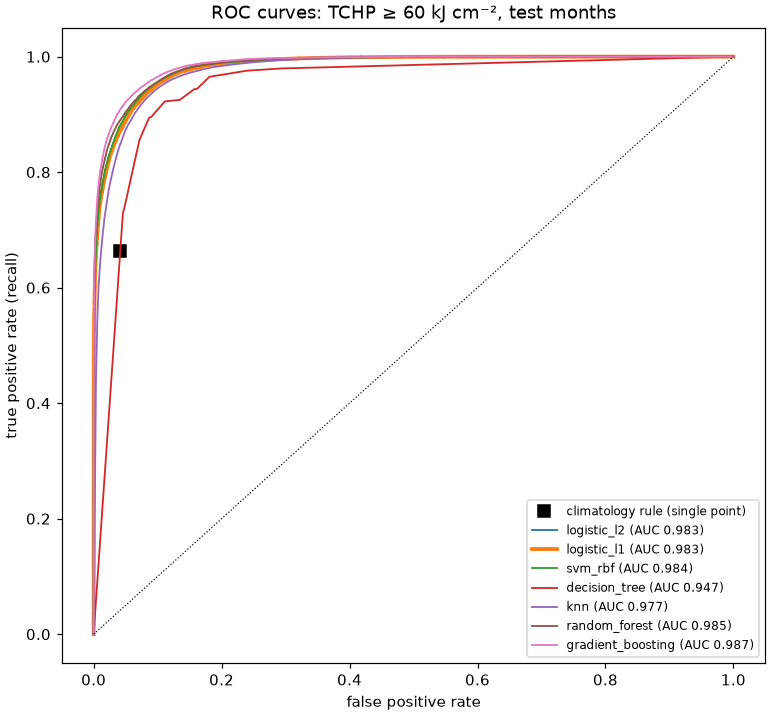

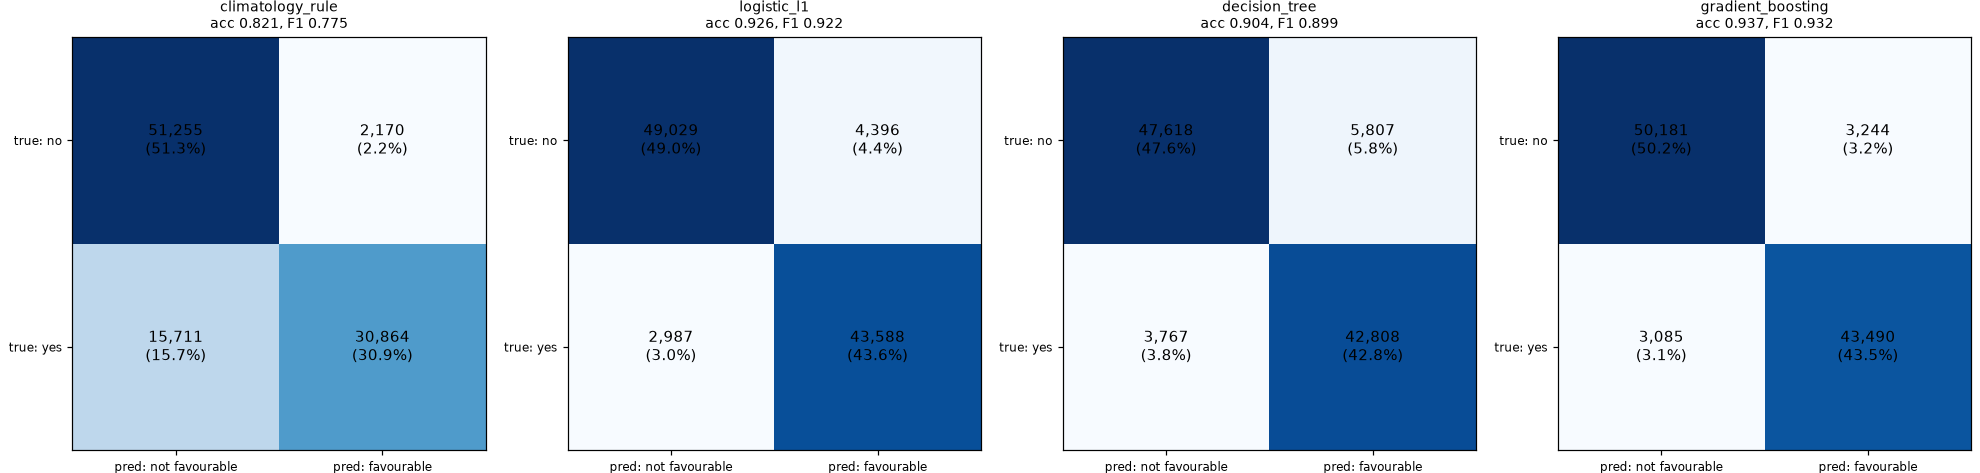

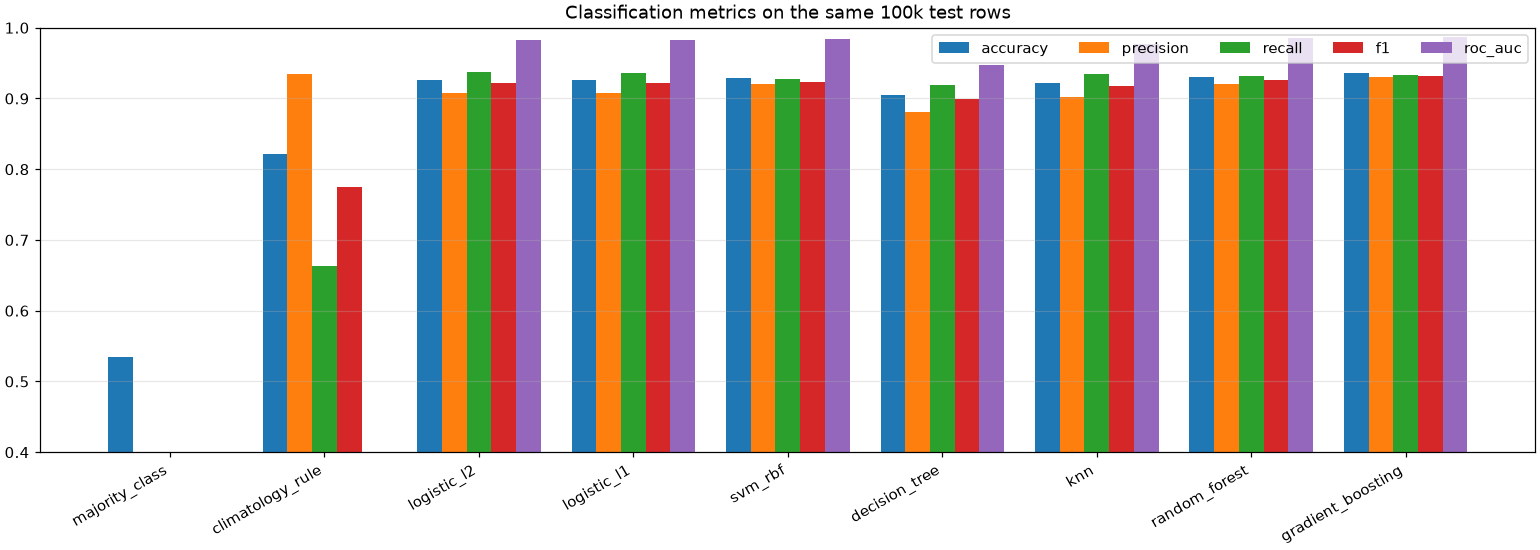

In [4]:
for f in ["01_roc_curves.png","02_confusion_matrices.png","03_metrics_comparison.png"]:
    display(Image(filename=str(FIGURES/"phase7"/f)))

## Regularization: overfitting and how it is controlled (validation curves, GroupKFold by month)
* **A/B.** A deliberately over-complex model (861 polynomial features, 2,000 rows) overfits without regularization; Ridge (L2) and Lasso (L1) fix it, and Lasso also selects features.
* **C.** Decision-tree depth: deeper trees memorise the training data (training accuracy → 1) while CV accuracy drops.
* **D.** Logistic regression: C = 1/λ.
* **E.** Gradient boosting: learning rate (shrinkage) × number of trees.

Ridge on 861 features: no regularization CV RMSE 5.306 °C (train 0.595) -> best alpha 3.16e+03: CV RMSE 1.246
Decision tree: best max_depth 4; at depth 30 train acc 1.000 vs CV 0.873


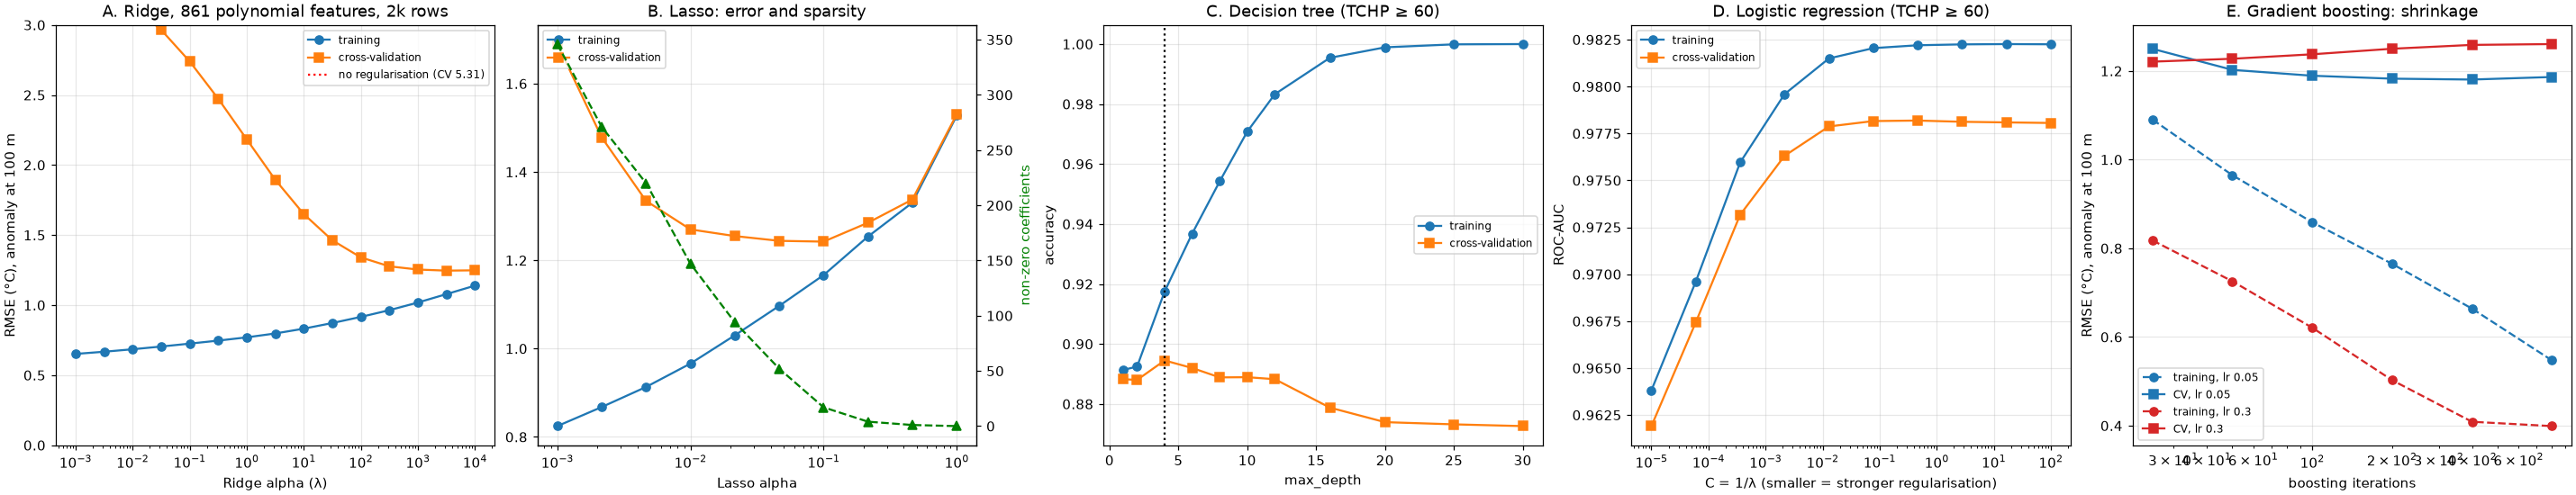

In [5]:
R = json.loads((ROOT/"results"/"phase7"/"regularization.json").read_text())
r = R["ridge_poly"]; print(f"Ridge on 861 features: no regularization CV RMSE {r['unregularised_cv_rmse']:.3f} °C (train {r['unregularised_train_rmse']:.3f}) -> best alpha {r['best_alpha']:.3g}: CV RMSE {r['best_cv_rmse']:.3f}")
t = R["tree_depth"]; print(f"Decision tree: best max_depth {t['best_depth']}; at depth 30 train acc {t['train_acc'][-1]:.3f} vs CV {t['cv_acc'][-1]:.3f}")
display(Image(filename=str(FIGURES/"phase7"/"04_regularization_curves.png")))